# EDA v2 — Assemblage des tableaux et corrélations

**Auteur :** Loan — branche `feature/assemblage`

**Entrées** (produites par les notebooks des autres, à exécuter localement, les CSV ne sont pas commités) :
- `output/elo_par_match.csv` — Moussa : une ligne par match de C1, Elo avant match ;
- `output/joueurs_par_match.csv` — Mouhamedou : une ligne par équipe et par match ;
- `output/fatigue_par_match.csv` — Ousmane : une ligne par club et par match.

**Sortie :** une grande table, **une ligne par match de C1**, avec les variables des trois fichiers.

`participants_2026.csv` et `calendrier_2026.csv` ne sont pas utilisés ici : ils ne sont pas au niveau du match (le calendrier concerne des matchs futurs, sans `game_id`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER_PROJET = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "output").is_dir()), None)
if DOSSIER_PROJET is None:
    raise FileNotFoundError("Dossier output/ introuvable. Exécute d'abord les notebooks Elo, joueurs et fatigue en local.")
OUT = DOSSIER_PROJET / "output"

FICHIERS = ["elo_par_match.csv", "joueurs_par_match.csv", "fatigue_par_match.csv"]
manquants = [f for f in FICHIERS if not (OUT / f).is_file()]
if manquants:
    raise FileNotFoundError("Fichier(s) absent(s) de output/ : " + ", ".join(manquants)
                            + ". Exécute le notebook correspondant en local.")

elo = pd.read_csv(OUT / "elo_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
joueurs = pd.read_csv(OUT / "joueurs_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
fatigue = pd.read_csv(OUT / "fatigue_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
print(f"elo : {len(elo):,} lignes | joueurs : {len(joueurs):,} | fatigue : {len(fatigue):,}")

elo : 1,871 lignes | joueurs : 3,742 | fatigue : 3,742


## 1. Vérifier la structure avant de fusionner

Attendu : un match apparaît **une fois** dans `elo` et **deux fois** dans `joueurs` et `fatigue` (une par équipe).

In [2]:
assert elo["game_id"].is_unique, "Un match est présent plusieurs fois dans elo_par_match.csv"
assert joueurs.groupby("game_id").size().eq(2).all(), "joueurs_par_match.csv : pas exactement 2 lignes par match"
assert fatigue.groupby("game_id").size().eq(2).all(), "fatigue_par_match.csv : pas exactement 2 lignes par match"
print("Structure conforme.")
print(f"Matchs de C1 dans elo : {elo['game_id'].nunique():,}")
print(f"Saisons : {sorted(elo['season'].unique())}")

Structure conforme.
Matchs de C1 dans elo : 1,871
Saisons : [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 2. Passer d'une ligne par équipe à une ligne par match

`joueurs` et `fatigue` ont une ligne par équipe. On les transforme en colonnes `dom_…` (domicile) et `ext_…` (extérieur), puis on fusionne sur `game_id`.

In [3]:
def par_cote(df, colonne_cote, valeur_dom, valeur_ext, colonnes, prefixe):
    # Une ligne par équipe -> une ligne par match, avec colonnes dom_<prefixe>… et ext_<prefixe>…
    morceaux = []
    for valeur, nom in [(valeur_dom, "dom"), (valeur_ext, "ext")]:
        t = df.loc[df[colonne_cote].eq(valeur), ["game_id"] + colonnes]
        morceaux.append(t.rename(columns={c: f"{nom}_{prefixe}{c}" for c in colonnes}))
    return morceaux[0].merge(morceaux[1], on="game_id", how="outer", validate="one_to_one")

cols_joueurs = [
    "club_id", "valeur_effectif_eur_avant_match", "age_moyen_joueurs_alignes",
    "nb_joueurs_utilises_championnat_precedent", "nb_joueurs_utilises_c1_precedent",
    "part_buts_meilleur_buteur_championnat_precedente", "part_buts_meilleur_buteur_c1_precedente",
    "buts_pour", "buts_contre", "resultat",
]
cols_fatigue = ["club_id", "jours_repos", "matchs_30j_avant", "nb_competitions_saison"]

g = elo.merge(par_cote(joueurs, "lieu", "Domicile", "Extérieur", cols_joueurs, "j_"),
              on="game_id", how="left", validate="one_to_one")
g = g.merge(par_cote(fatigue, "cote", "Domicile", "Extérieur", cols_fatigue, "f_"),
            on="game_id", how="left", validate="one_to_one")

# Contrôle : le club de domicile est bien le même dans les trois fichiers
print(f"Club domicile identique (elo / joueurs) : {(g['dom_j_club_id'] == g['home_club_id']).mean():.1%}")
print(f"Club domicile identique (elo / fatigue) : {(g['dom_f_club_id'] == g['home_club_id']).mean():.1%}")
print(f"Grande table : {g.shape[0]:,} matchs × {g.shape[1]} colonnes")

Club domicile identique (elo / joueurs) : 100.0%
Club domicile identique (elo / fatigue) : 100.0%
Grande table : 1,871 matchs × 41 colonnes


## 3. Variable à expliquer et écarts entre équipes

- `score_domicile` : 1 = victoire à domicile, 0,5 = nul, 0 = défaite (même codage que l'Elo).
- Les écarts sont calculés **domicile moins extérieur**. Un écart positif favorise l'équipe à domicile.
- La valeur d'effectif est très asymétrique : on utilise son logarithme décimal.

In [4]:
# Cohérence : une victoire de l'un est une défaite de l'autre
verif = g["dom_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0}) \
      + g["ext_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0})
assert verif.dropna().eq(1).all(), "Résultats incohérents entre les deux équipes"

g["score_domicile"] = g["dom_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0})

g["ecart_elo_global"] = g["home_elo_global"] - g["away_elo_global"]
g["ecart_elo_c1"] = g["home_elo_c1"] - g["away_elo_c1"]
g["ecart_elo_championnat"] = g["home_elo_champ"] - g["away_elo_champ"]

val_dom = g["dom_j_valeur_effectif_eur_avant_match"].where(lambda x: x > 0)
val_ext = g["ext_j_valeur_effectif_eur_avant_match"].where(lambda x: x > 0)
g["ecart_log_valeur_effectif"] = np.log10(val_dom) - np.log10(val_ext)

g["ecart_age_moyen"] = g["dom_j_age_moyen_joueurs_alignes"] - g["ext_j_age_moyen_joueurs_alignes"]
g["ecart_rotation_championnat"] = (g["dom_j_nb_joueurs_utilises_championnat_precedent"]
                                   - g["ext_j_nb_joueurs_utilises_championnat_precedent"])
g["ecart_rotation_c1"] = g["dom_j_nb_joueurs_utilises_c1_precedent"] - g["ext_j_nb_joueurs_utilises_c1_precedent"]
g["ecart_meilleur_buteur_championnat"] = (g["dom_j_part_buts_meilleur_buteur_championnat_precedente"]
                                          - g["ext_j_part_buts_meilleur_buteur_championnat_precedente"])
g["ecart_meilleur_buteur_c1"] = (g["dom_j_part_buts_meilleur_buteur_c1_precedente"]
                                 - g["ext_j_part_buts_meilleur_buteur_c1_precedente"])

g["ecart_jours_repos"] = g["dom_f_jours_repos"] - g["ext_f_jours_repos"]
# Les écarts supérieurs à 14 jours viennent surtout de trous de couverture (pauses estivales, compétitions absentes de games.csv) : on les borne
g["ecart_jours_repos_borne"] = g["ecart_jours_repos"].clip(-14, 14)
g["ecart_matchs_30j"] = g["dom_f_matchs_30j_avant"] - g["ext_f_matchs_30j_avant"]
g["ecart_nb_competitions"] = g["dom_f_nb_competitions_saison"] - g["ext_f_nb_competitions_saison"]

VARIABLES_UTILES = [
    "ecart_elo_global", "ecart_elo_c1", "ecart_elo_championnat", "ecart_log_valeur_effectif",
    "ecart_age_moyen", "ecart_rotation_championnat", "ecart_rotation_c1",
    "ecart_meilleur_buteur_championnat", "ecart_meilleur_buteur_c1",
    "ecart_jours_repos_borne", "ecart_matchs_30j", "ecart_nb_competitions",
    "score_domicile",
]
print(f"{len(VARIABLES_UTILES) - 1} variables explicatives + la cible.")

12 variables explicatives + la cible.


## 4. `describe()` : ordres de grandeur et valeurs bizarres

In [5]:
g[VARIABLES_UTILES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ecart_elo_global,1871.0,-0.15,123.62,-397.82,-82.45,-0.71,82.53,420.78
ecart_elo_c1,1789.0,-0.49,109.71,-358.94,-66.61,-0.79,65.01,384.20
ecart_elo_championnat,1566.0,-0.53,106.51,-359.74,-69.51,-0.35,68.28,344.56
ecart_log_valeur_effectif,1766.0,0.01,0.81,-3.25,-0.39,-0.00,0.39,3.37
ecart_age_moyen,1766.0,-0.01,2.21,-7.03,-1.54,0.05,1.47,8.54
ecart_rotation_championnat,1397.0,0.03,5.05,-27.00,-3.00,0.00,3.00,27.00
ecart_rotation_c1,710.0,0.09,6.82,-23.00,-2.00,0.00,3.00,24.00
ecart_meilleur_buteur_championnat,1397.0,-0.00,0.13,-0.77,-0.08,0.00,0.08,0.77
ecart_meilleur_buteur_c1,671.0,-0.00,0.19,-0.83,-0.12,-0.00,0.11,0.84
ecart_jours_repos_borne,1871.0,0.02,5.52,-14.00,-1.00,0.00,0.00,14.00


In [6]:
print("Valeurs manquantes par variable :")
print(g[VARIABLES_UTILES].isna().sum().to_string())

# Valeurs bizarres à vérifier avant de conclure
controles = {
    "jours de repos négatifs (dom + ext)": int((g["dom_f_jours_repos"] < 0).sum() + (g["ext_f_jours_repos"] < 0).sum()),
    "jours de repos > 60": int((g["dom_f_jours_repos"] > 60).sum() + (g["ext_f_jours_repos"] > 60).sum()),
    "âge moyen hors 15-45 ans": int((g["dom_j_age_moyen_joueurs_alignes"].notna()
                                     & ~g["dom_j_age_moyen_joueurs_alignes"].between(15, 45)).sum()
                                    + (g["ext_j_age_moyen_joueurs_alignes"].notna()
                                       & ~g["ext_j_age_moyen_joueurs_alignes"].between(15, 45)).sum()),
    "valeur d'effectif nulle": int((g["dom_j_valeur_effectif_eur_avant_match"] == 0).sum()
                                   + (g["ext_j_valeur_effectif_eur_avant_match"] == 0).sum()),
    "Elo hors 1000-2500": int((~g["home_elo_global"].between(1000, 2500)).sum()
                              + (~g["away_elo_global"].between(1000, 2500)).sum()),
}
pd.Series(controles, name="nombre").to_frame()

Valeurs manquantes par variable :
ecart_elo_global                        0
ecart_elo_c1                           82
ecart_elo_championnat                 305
ecart_log_valeur_effectif             105
ecart_age_moyen                       105
ecart_rotation_championnat            474
ecart_rotation_c1                    1161
ecart_meilleur_buteur_championnat     474
ecart_meilleur_buteur_c1             1200
ecart_jours_repos_borne                 0
ecart_matchs_30j                        0
ecart_nb_competitions                   0
score_domicile                          0


,nombre
jours de repos négatifs (dom + ext),0
jours de repos > 60,19
âge moyen hors 15-45 ans,0
valeur d'effectif nulle,0
Elo hors 1000-2500,0


## 5. Matrice de corrélation

Deux mesures : **Pearson** (relation linéaire) et **Spearman** (relation monotone, moins sensible aux valeurs extrêmes, utile pour la valeur d'effectif). Les identifiants sont exclus.

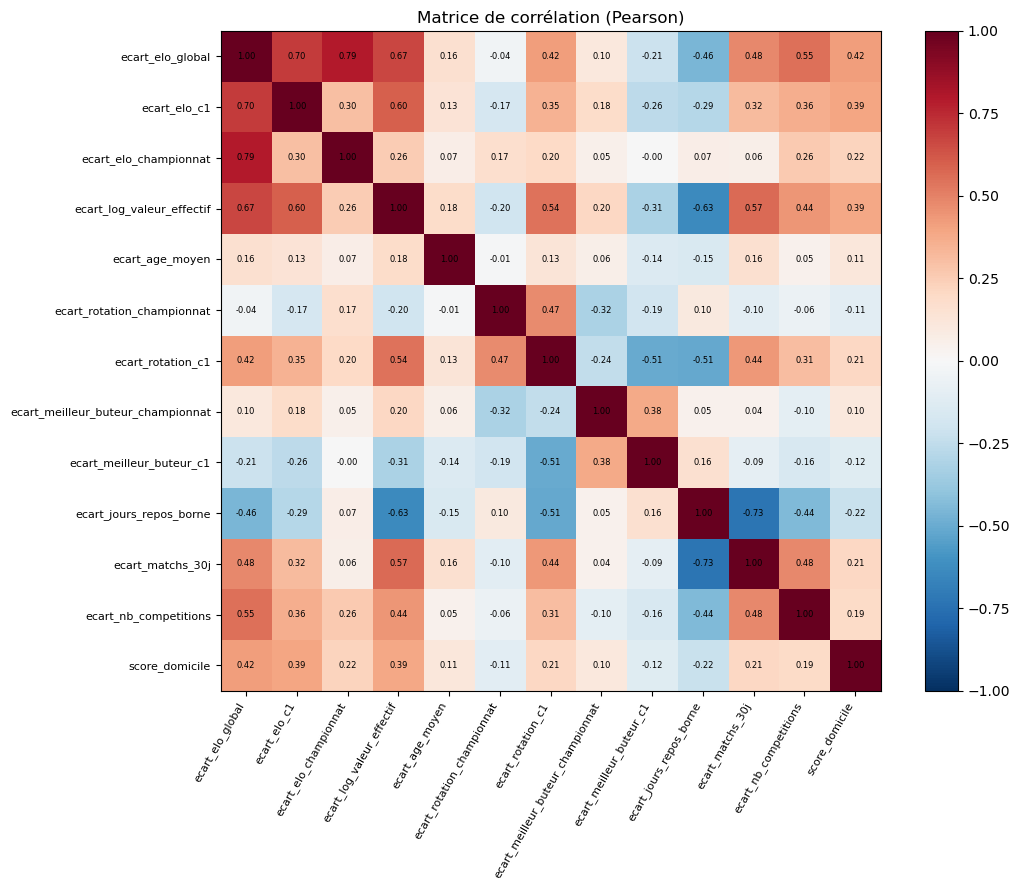

In [7]:
corr = g[VARIABLES_UTILES].corr(method="pearson")
corr_sp = g[VARIABLES_UTILES].corr(method="spearman")

n = len(VARIABLES_UTILES)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(VARIABLES_UTILES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(n))
ax.set_yticklabels(VARIABLES_UTILES, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Matrice de corrélation (Pearson)")
plt.tight_layout()
plt.show()

## 6. Quelles variables sont liées au résultat ?

In [8]:
lien_resultat = pd.DataFrame({
    "pearson": corr["score_domicile"],
    "spearman": corr_sp["score_domicile"],
}).drop(index="score_domicile")
lien_resultat.sort_values("spearman", key=abs, ascending=False).round(3)

,pearson,spearman
ecart_log_valeur_effectif,0.389,0.446
ecart_elo_global,0.416,0.416
ecart_elo_c1,0.393,0.404
ecart_elo_championnat,0.220,0.221
ecart_jours_repos_borne,-0.221,-0.216
ecart_rotation_c1,0.210,0.191
ecart_nb_competitions,0.190,0.180
ecart_matchs_30j,0.206,0.173
ecart_rotation_championnat,-0.107,-0.126
ecart_meilleur_buteur_championnat,0.105,0.111


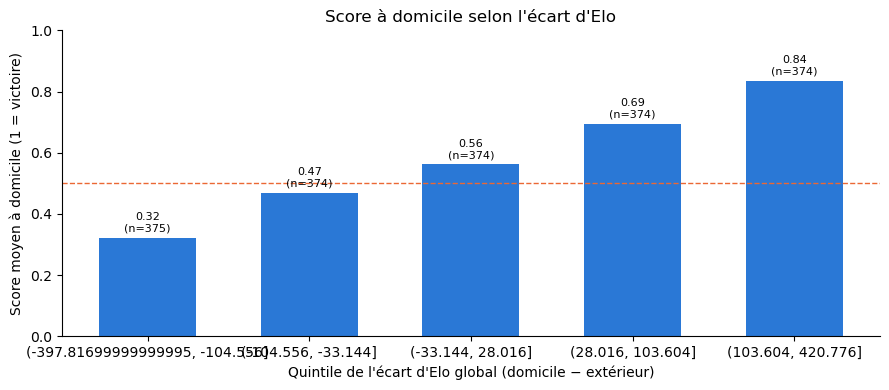

In [9]:
# Score moyen à domicile (victoire = 1, nul = 0,5) par quintile d'écart d'Elo global
quintiles = pd.qcut(g["ecart_elo_global"], 5)
par_quintile = g.groupby(quintiles, observed=True)["score_domicile"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([str(i) for i in par_quintile.index], par_quintile["mean"], color="#2a78d6", width=0.6)
ax.axhline(0.5, color="#eb6834", linestyle="--", linewidth=1)
for x, (moy, nb) in enumerate(zip(par_quintile["mean"], par_quintile["size"])):
    ax.text(x, moy + 0.02, f"{moy:.2f}\n(n={nb})", ha="center", fontsize=8)
ax.set_ylim(0, 1)
ax.set_xlabel("Quintile de l'écart d'Elo global (domicile − extérieur)")
ax.set_ylabel("Score moyen à domicile (1 = victoire)")
ax.set_title("Score à domicile selon l'écart d'Elo")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Les variables se répètent-elles entre elles ?

Deux variables explicatives très corrélées (|r| ≥ 0,5) apportent la même information : il ne faut pas les garder ensemble dans un modèle sans précaution.

In [10]:
predicteurs = [v for v in VARIABLES_UTILES if v != "score_domicile"]
paires = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(predicteurs) for b in predicteurs[i + 1:]
    if abs(corr.loc[a, b]) >= 0.5
]
pd.DataFrame(paires, columns=["variable_1", "variable_2", "pearson"]) \
    .sort_values("pearson", key=abs, ascending=False)

,variable_1,variable_2,pearson
1,ecart_elo_global,ecart_elo_championnat,0.791
10,ecart_jours_repos_borne,ecart_matchs_30j,-0.734
0,ecart_elo_global,ecart_elo_c1,0.701
2,ecart_elo_global,ecart_log_valeur_effectif,0.670
6,ecart_log_valeur_effectif,ecart_jours_repos_borne,-0.634
4,ecart_elo_c1,ecart_log_valeur_effectif,0.601
7,ecart_log_valeur_effectif,ecart_matchs_30j,0.567
3,ecart_elo_global,ecart_nb_competitions,0.552
5,ecart_log_valeur_effectif,ecart_rotation_c1,0.542
9,ecart_rotation_c1,ecart_jours_repos_borne,-0.511


## 8. Interprétation

- Les variables les plus liées au résultat sont l'écart de valeur d'effectif (Spearman 0,446), l'écart d'Elo global (0,416) et l'écart d'Elo C1 (0,404). Le signe est positif : plus l'équipe à domicile est forte, plus elle gagne.
- L'écart d'Elo championnat est nettement plus faible (0,22). Cela confirme le constat de Moussa : un Elo national ne compare pas bien des clubs de pays différents.
- Le repos a un lien négatif avec le résultat : un club à domicile plus reposé gagne moins souvent (corrélation de -0,22 avec la variable bornée à ±14 jours, Pearson et Spearman concordants). Ce sens est contre-intuitif. Une explication possible est que les clubs plus reposés sont ceux qui jouent moins de compétitions, donc souvent moins forts. C'est une hypothèse : il faudrait la tester en contrôlant par l'écart d'Elo.
- Variables qui se répètent : l'Elo global est corrélé à l'Elo championnat (0,79), à l'Elo C1 (0,70) et à la valeur d'effectif (0,67). Elles mesurent surtout le même niveau. La valeur d'effectif est aussi liée aux matchs sur 30 jours (0,57).
- L'écart de repos borné est fortement lié à l'écart de matchs sur 30 jours (-0,73) et à l'écart de valeur d'effectif (-0,63) : les clubs les plus riches jouent plus souvent et se reposent moins. Cela va dans le sens de l'hypothèse ci-dessus sur le lien négatif entre repos et résultat.
- La rotation C1 et la part du meilleur buteur C1 sont liées négativement (-0,51) : elles décrivent le même phénomène sous deux angles.

## 9. Limite : la météo

*Argument, sans données météo dans le projet.* Le dépôt ne contient aucune donnée de température, de pluie ou de vent par match. Or le temps peut modifier le jeu (terrain lourd, vent, chaleur en fin d'été) et donc le résultat. Nous ne pouvons donc pas mesurer son effet. Pour le tester, il faudrait joindre à chaque match la météo du stade à l'heure du coup d'envoi (source ouverte à identifier, par exemple Meteostat), puis vérifier si elle améliore la corrélation ou le modèle. En attendant, la météo reste une **limite** du modèle, et nos résultats valent pour les conditions moyennes des matchs passés.

## 10. Corrélation ≠ causalité

Les variables ci-dessus sont **liées** au résultat, elles n'en sont pas la **cause** prouvée. Exemple : un écart d'Elo élevé et une victoire vont souvent ensemble parce que l'Elo résume le niveau de l'équipe, pas parce que l'Elo fait gagner. Une corrélation peut aussi venir d'une troisième variable (un club riche a à la fois une grande valeur d'effectif et plus de victoires). Nos résultats décrivent des associations observées sur les matchs passés.

In [11]:
OUT.mkdir(parents=True, exist_ok=True)
chemin = OUT / "eda_matchs_c1.csv"
g.to_csv(chemin, index=False, encoding="utf-8-sig")
print(f"Grande table écrite : {chemin} ({len(g):,} matchs)")

Grande table écrite : C:\Users\loan0\Documents\Projet-datascience\CHAMPIONS-\output\eda_matchs_c1.csv (1,871 matchs)


## 11. Conclusion

*3 découvertes*
1. L'écart d'Elo global et l'écart de valeur d'effectif sont les variables les plus liées au résultat. Par quintile d'Elo, le score moyen à domicile (victoire = 1, nul = 0,5) va de 0,32 (écart le plus défavorable) à 0,84 (écart le plus favorable).
2. L'Elo championnat (0,22) est beaucoup moins lié au résultat que l'Elo global ou l'Elo C1 : il ne doit pas servir seul pour la C1.
3. Le repos a un lien négatif avec le résultat (-0,22), contre-intuitif, probablement lié au niveau des équipes plutôt qu'à la fatigue elle-même.

*2 limites*
1. La rotation C1 n'existe que pour 710 matchs sur 1 871, et l'écart de repos contient des trous de couverture (pauses, compétitions absentes de `games.csv`), d'où la borne à ±14 jours.
2. Il n'y a aucune donnée météo, et les corrélations ne contrôlent pas le niveau des équipes : corrélation ≠ causalité.

*1 question à poursuivre*
L'Elo global seul fait-il mieux que 56 % sur les matchs de C1, et la valeur d'effectif ajoute-t-elle quelque chose une fois l'Elo pris en compte ?

*À reporter dans `README.md` (fait par Loan) :* liste des fichiers d'entrée, ordre d'exécution des notebooks, et ce qui est commité ou ignoré.